| Nama              | NRP        |
|-------------------|------------|
| Muhammad Dayyan Ghazanfar Latief         | 5054241036     |

# Segmentasi Citra Berbasis Diskontinuitas dan Segmentasi Berbasis Similaritas

## Deskripsi Tugas
Cari  beberapa jenis citra digital dengan karakteristik berbeda. lakukan segmentasi menggunakan metode berbasis **Diskontinuitas** dan **Similaritas**, kemudian lakukan analisis komparatif terhadap hasilnya tiap methods.

# I. Segmentasi Berbasis Diskontinuitas

Implementasikan metode:
- Sobel Edge Detection
- Canny Edge Detection
- Laplacian of Gaussian (LoG)

Setelah deteksi tepi, terapkan edge linking . Tunjukkan perbandingan hasil sebelum dan sesudah penerapannya.

# II. Segmentasi Berbasis Similaritas
Implementasikan metode pengelompokan piksel menggunakan :
- Otsu Thresholding
- Adaptive Thresholding
- K-Means Clustering (tentukan jumlah cluster K dan jelaskan alasan pemilihannya)


# III. Dataset
Gunakan 3 citra digital, masing-masing mewakili satu karakteristik berikut:

- Citra 1 —  Citra langit
- Citra 2 — Objek berhimpitan
- Citra 3 — Dokumen kusam / berbayang

reference:
-
- https://github.com/CXH-Research/DocShadow-SD7K
- https://cs.adelaide.edu.au/~carneiro/isbi14_challenge/

# IV. Implementasi

Untuk setiap citra:

## 1. Input dan Preprocessing

* Load image
* Grayscale conversion
* Filtering / smoothing bila diperlukan

---

## 2. Segmentasi Berbasis Diskontinuitas

* Sobel
* Canny
* LoG

Tampilkan:

* hasil edge detection,
* hasil segmentasi akhir.

---

## 3. Segmentasi Berbasis Similaritas

* Otsu
* Adaptive Threshold
* K-Means

Tampilkan:

* hasil threshold/clustering,
* hasil segmentasi akhir.

---

# V. Analisis

Berikan analisis mengenai:

- Kualitas segmentasi
- kelebihan dan kekurragan metode
- Kesesuaian metode terhadap karakteristik citra

### Citra 1: Analisis Citra Langit

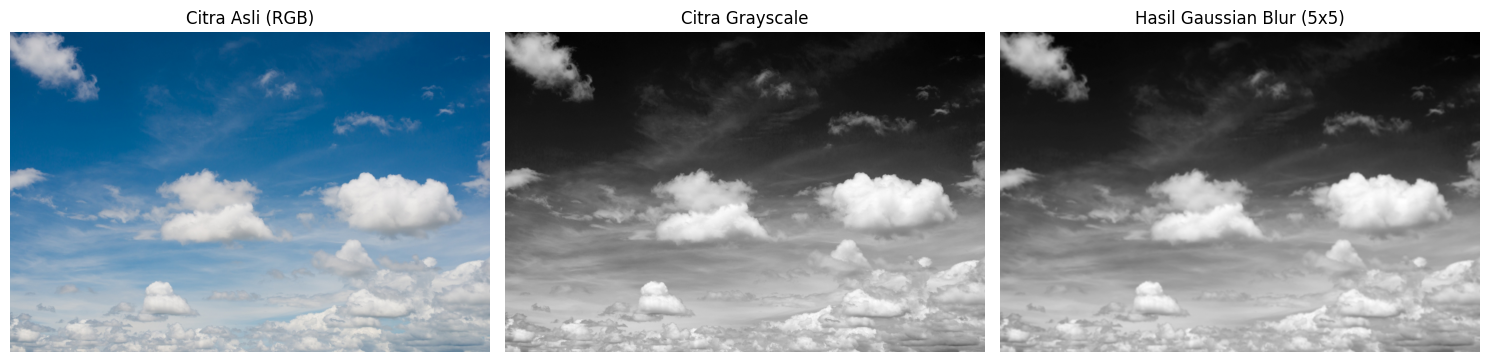

In [27]:
# 1. Preprocessing
import cv2
import numpy as np
import matplotlib.pyplot as plt

image_path_1 = 'citra-langit.jpg' 
img_1 = cv2.imread(image_path_1)

img_1_rgb = cv2.cvtColor(img_1, cv2.COLOR_BGR2RGB)
img_1_gray = cv2.cvtColor(img_1, cv2.COLOR_BGR2GRAY)
img_1_blurred = cv2.GaussianBlur(img_1_gray, (5, 5), 0)

# Visualisasi

plt.figure(figsize=(15, 5))

# Plot Citra Asli
plt.subplot(1, 3, 1)
plt.imshow(img_1_rgb)
plt.title("Citra Asli (RGB)")
plt.axis('off')

# Plot Grayscale
plt.subplot(1, 3, 2)
plt.imshow(img_1_gray, cmap='gray')
plt.title("Citra Grayscale")
plt.axis('off')

# Plot Blur
plt.subplot(1, 3, 3)
plt.imshow(img_1_blurred, cmap='gray')
plt.title("Hasil Gaussian Blur (5x5)")
plt.axis('off')

plt.tight_layout()
plt.show()

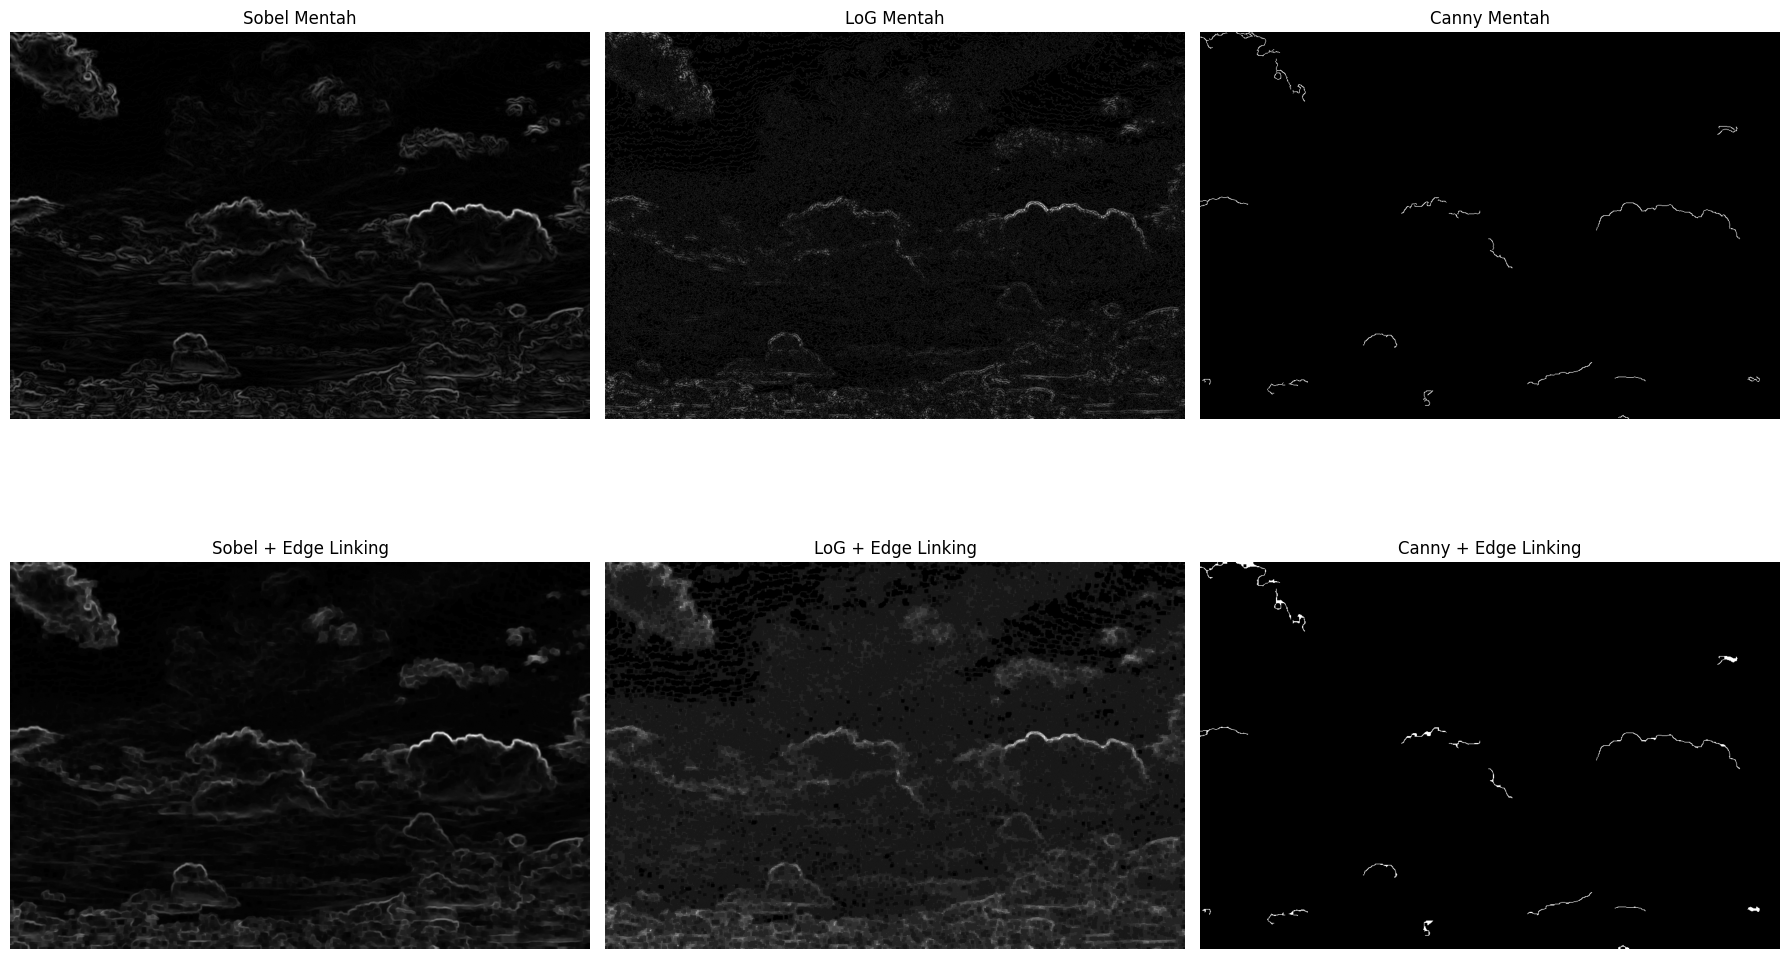

In [28]:
# 2. Segmentasi Diskontinuitas

kernel = np.ones((5,5), np.uint8)

# 1. Sobel Edge Detection
sobelx = cv2.Sobel(img_1_blurred, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(img_1_blurred, cv2.CV_64F, 0, 1, ksize=3)
sobel_combined = cv2.magnitude(sobelx, sobely)
sobel_combined = np.uint8(255 * sobel_combined / np.max(sobel_combined))
# Sobel Edge Linking
sobel_linked = cv2.morphologyEx(sobel_combined, cv2.MORPH_CLOSE, kernel)

# 2. Laplacian of Gaussian (LoG)
laplacian = cv2.Laplacian(img_1_blurred, cv2.CV_64F)
laplacian = np.uint8(np.absolute(laplacian))
# LOG Edge Linking
log_linked = cv2.morphologyEx(laplacian, cv2.MORPH_CLOSE, kernel)

# 3. Canny Edge Detection
canny = cv2.Canny(img_1_blurred, 50, 150)
# Canny Edge Linking
canny_linked = cv2.morphologyEx(canny, cv2.MORPH_CLOSE, kernel)

# Visualisasi
plt.figure(figsize=(18, 12))

# Baris 1: Hasil Mentah
plt.subplot(2, 3, 1)
plt.imshow(sobel_combined, cmap='gray')
plt.title("Sobel Mentah")
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(laplacian, cmap='gray')
plt.title("LoG Mentah")
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(canny, cmap='gray')
plt.title("Canny Mentah")
plt.axis('off')

# Baris 2: Hasil setelah Edge Linking
plt.subplot(2, 3, 4)
plt.imshow(sobel_linked, cmap='gray')
plt.title("Sobel + Edge Linking")
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(log_linked, cmap='gray')
plt.title("LoG + Edge Linking")
plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(canny_linked, cmap='gray')
plt.title("Canny + Edge Linking")
plt.axis('off')

plt.tight_layout()
plt.show()

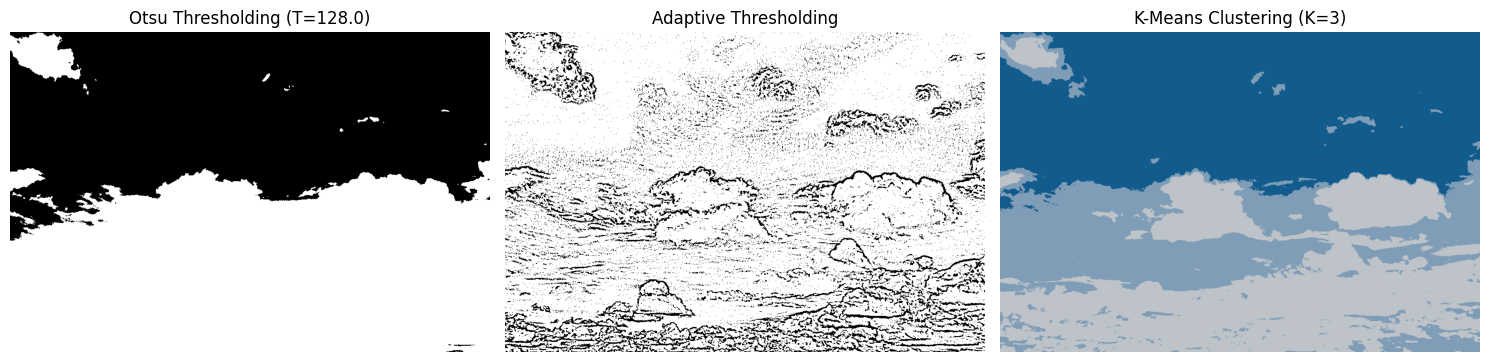

In [29]:
# 3. Segmentasi Similaritas

# 1. Otsu Thresholding (Global)
ret_otsu, otsu_result = cv2.threshold(img_1_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 2. Adaptive Thresholding (Lokal)
adaptive_result = cv2.adaptiveThreshold(img_1_gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                        cv2.THRESH_BINARY, 11, 2)

# 3. K-Means Clustering (Berbasis Warna RGB)
pixel_values = img_1_rgb.reshape((-1, 3))
pixel_values = np.float32(pixel_values)

k_clusters = 3
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)
_, labels, centers = cv2.kmeans(pixel_values, k_clusters, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

centers = np.uint8(centers)
kmeans_result = centers[labels.flatten()].reshape(img_1_rgb.shape)

# Visualisasi
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(otsu_result, cmap='gray')
plt.title(f"Otsu Thresholding (T={ret_otsu})")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(adaptive_result, cmap='gray')
plt.title("Adaptive Thresholding")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(kmeans_result)
plt.title(f"K-Means Clustering (K={k_clusters})")
plt.axis('off')

plt.tight_layout()
plt.show()

**Analisis Citra 1:**

* **Kualitas Segmentasi:** 
    * **Diskontinuitas:** Gagal total. Hanya menghasilkan *noise* acak tanpa membentuk kontur awan yang jelas.
    * **Similaritas:** K-Means (K=3) memberikan hasil paling rapi dan natural. Otsu terlalu kaku (biner), dan Adaptive Thresholding hancur penuh *noise*.

* **Kelebihan Metode:** 
    * **K-Means:** Sangat unggul memetakan gradasi (langit biru, awan tebal, awan transisi) berdasarkan kemiripan warna tanpa butuh garis tepi fisik.
    * **Otsu:** Komputasi cepat untuk pemisahan global terang-gelap, meski detail hilang.

* **Kekurangan Metode:** 
    * **Diskontinuitas (Canny/Sobel/LoG):** Gagal mendeteksi tepi karena awan memudar perlahan. Magnitudo gradiennya terlalu lemah.
    * **Adaptive Thresholding:** Menciptakan *noise* kotor karena kebingungan mencari nilai ambang batas lokal di area langit yang warnanya solid (varians mendekati nol).
    * **Otsu:** Membuang informasi warna RGB menjadi biner, sehingga awan tipis hilang tertelan latar belakang hitam.

* **Kesesuaian Metode:** 
    * **Sangat Sesuai:** K-Means Clustering. Tepat untuk objek gas/awan yang tidak punya garis tepi nyata tapi memiliki kedekatan ruang warna.
    * **Sangat Tidak Sesuai:** Semua metode deteksi tepi dan Adaptive Thresholding.

### Citra 2: Analisis Citra Tumpukan Koin

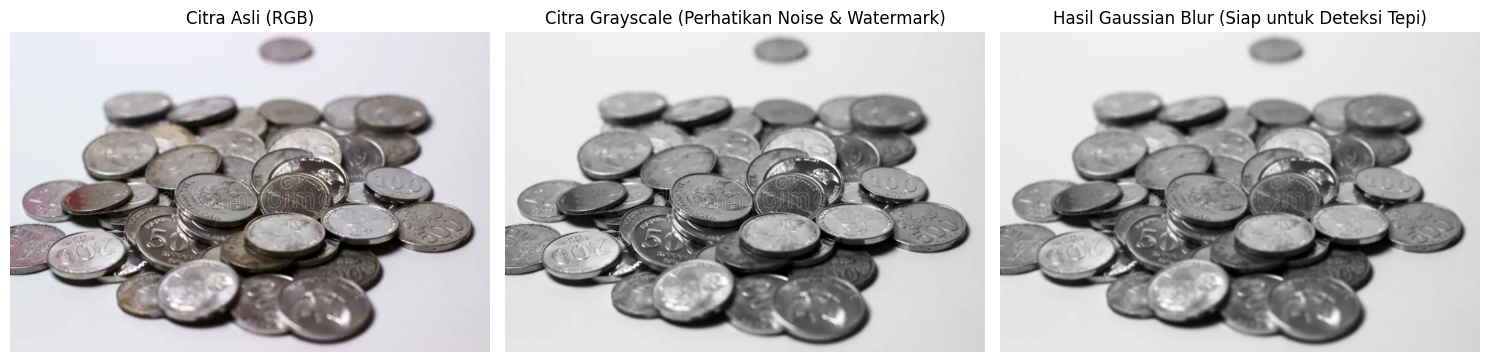

In [30]:
# 1. Preprocessing
import cv2
import numpy as np
import matplotlib.pyplot as plt

image_path_2 = 'koin-berhimpitan.webp' 
img_2 = cv2.imread(image_path_2)

img_2_rgb = cv2.cvtColor(img_2, cv2.COLOR_BGR2RGB)
img_2_gray = cv2.cvtColor(img_2, cv2.COLOR_BGR2GRAY)
img_2_blurred = cv2.GaussianBlur(img_2_gray, (5, 5), 0)

# Visualisasi

plt.figure(figsize=(15, 5))

# Plot Citra Asli
plt.subplot(1, 3, 1)
plt.imshow(img_2_rgb)
plt.title("Citra Asli (RGB)")
plt.axis('off')

# Plot Grayscale
plt.subplot(1, 3, 2)
plt.imshow(img_2_gray, cmap='gray')
plt.title("Citra Grayscale (Perhatikan Noise & Watermark)")
plt.axis('off')

# Plot Blurred
plt.subplot(1, 3, 3)
plt.imshow(img_2_blurred, cmap='gray')
plt.title("Hasil Gaussian Blur (Siap untuk Deteksi Tepi)")
plt.axis('off')

plt.tight_layout()
plt.show()

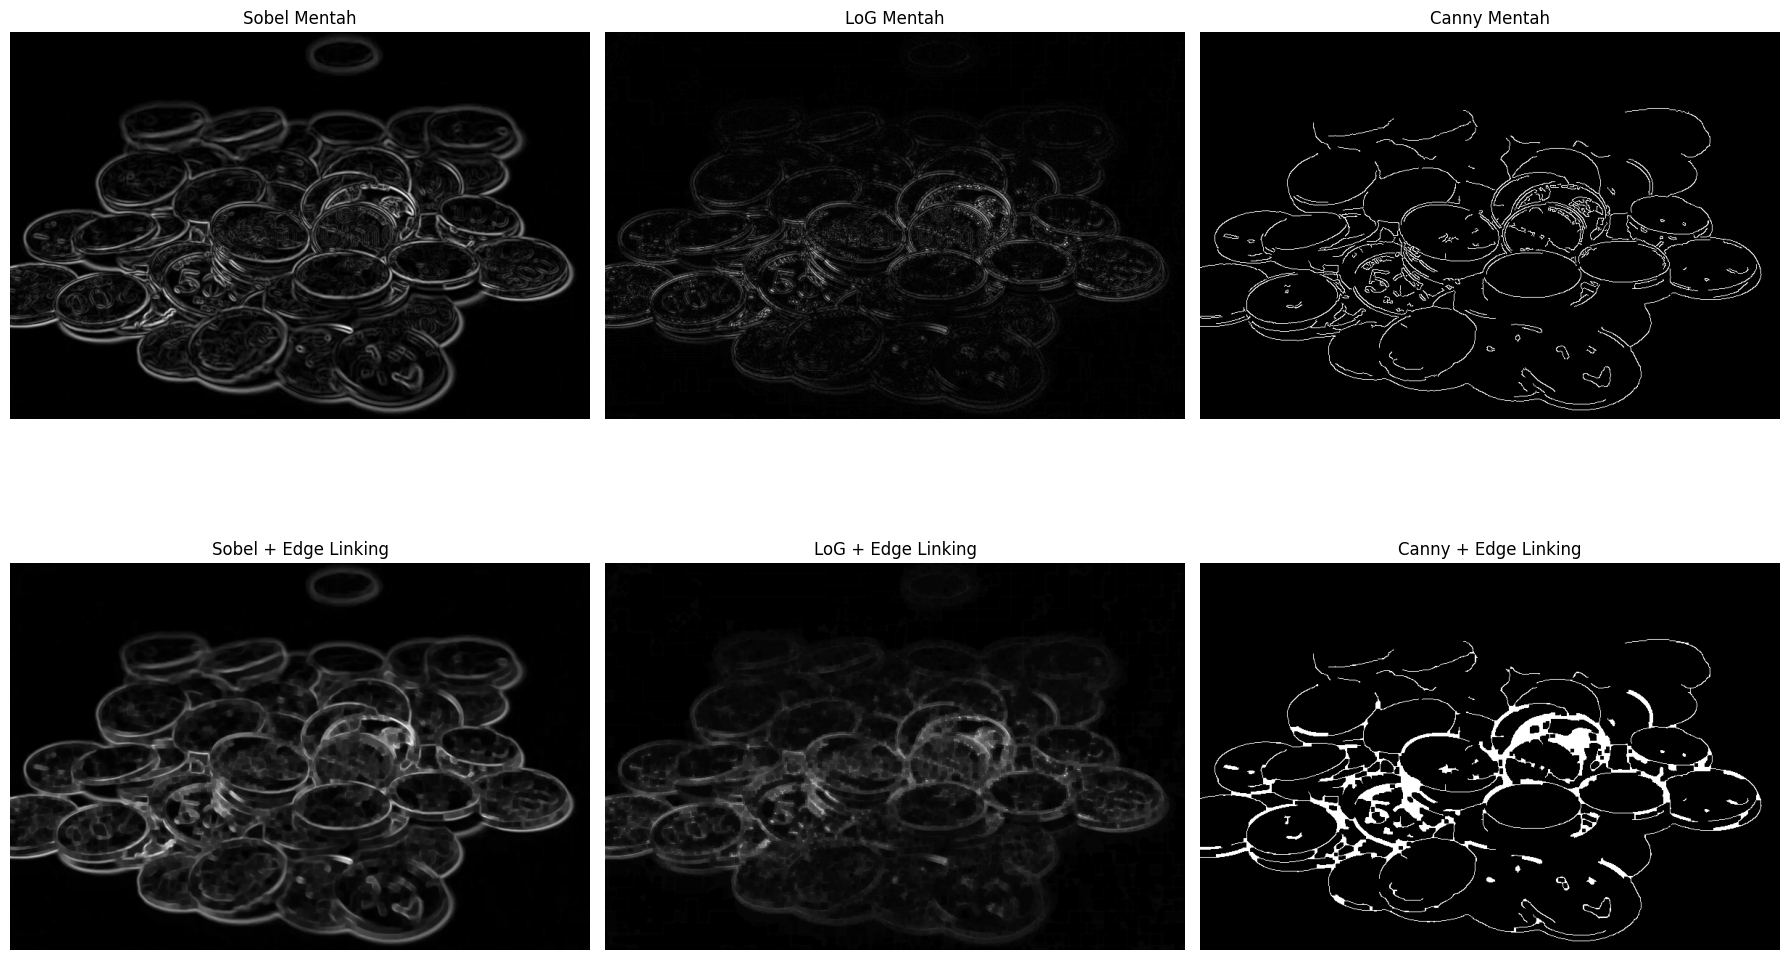

In [31]:
# 2. Segmentasi Diskontinuitas

kernel_2 = np.ones((5,5), np.uint8)

# 1. Sobel Edge Detection
sobelx_2 = cv2.Sobel(img_2_blurred, cv2.CV_64F, 1, 0, ksize=3)
sobely_2 = cv2.Sobel(img_2_blurred, cv2.CV_64F, 0, 1, ksize=3)
sobel_combined_2 = cv2.magnitude(sobelx_2, sobely_2)
sobel_combined_2 = np.uint8(255 * sobel_combined_2 / np.max(sobel_combined_2))
# Edge Linking pada Sobel
sobel_linked = cv2.morphologyEx(sobel_combined_2, cv2.MORPH_CLOSE, kernel_2)

# 2. Laplacian of Gaussian (LoG)
laplacian_2 = cv2.Laplacian(img_2_blurred, cv2.CV_64F)
laplacian_2 = np.uint8(np.absolute(laplacian_2))
# Edge Linking pada LoG
log_linked = cv2.morphologyEx(laplacian_2, cv2.MORPH_CLOSE, kernel_2)

# 3. Canny Edge Detection
canny_2 = cv2.Canny(img_2_blurred, 100, 200)
# Edge Linking pada Canny
canny_linked = cv2.morphologyEx(canny_2, cv2.MORPH_CLOSE, kernel_2)

# Visualisasi
plt.figure(figsize=(18, 12))

# Baris 1: Hasil Mentah
plt.subplot(2, 3, 1)
plt.imshow(sobel_combined_2, cmap='gray')
plt.title("Sobel Mentah")
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(laplacian_2, cmap='gray')
plt.title("LoG Mentah")
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(canny_2, cmap='gray')
plt.title("Canny Mentah")
plt.axis('off')

# Baris 2: Hasil setelah Edge Linking
plt.subplot(2, 3, 4)
plt.imshow(sobel_linked, cmap='gray')
plt.title("Sobel + Edge Linking")
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(log_linked, cmap='gray')
plt.title("LoG + Edge Linking")
plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(canny_linked, cmap='gray')
plt.title("Canny + Edge Linking")
plt.axis('off')

plt.tight_layout()
plt.show()

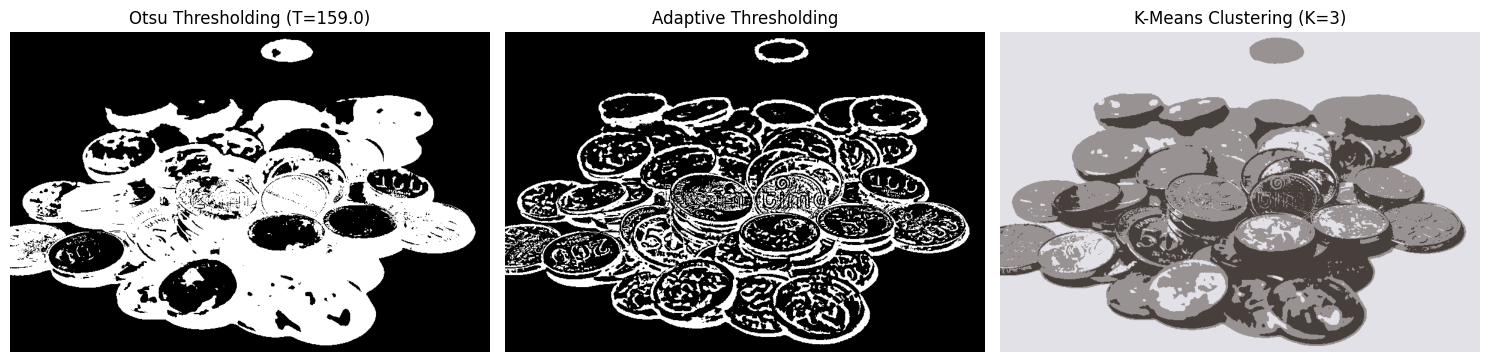

In [32]:
# 3. Segmentasi Similaritas

# 1. Otsu Thresholding (Global)
ret_otsu_2, otsu_result_2 = cv2.threshold(img_2_gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# 2. Adaptive Thresholding (Lokal)
adaptive_result_2 = cv2.adaptiveThreshold(img_2_gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                        cv2.THRESH_BINARY_INV, 21, 5)

# 3. K-Means Clustering (Berbasis Warna RGB)
pixel_values_2 = img_2_rgb.reshape((-1, 3))
pixel_values_2 = np.float32(pixel_values_2)

k_clusters_2 = 3
criteria_2 = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)
_, labels_2, centers_2 = cv2.kmeans(pixel_values_2, k_clusters_2, None, criteria_2, 10, cv2.KMEANS_RANDOM_CENTERS)

centers_2 = np.uint8(centers_2)
kmeans_result_2 = centers_2[labels_2.flatten()].reshape(img_2_rgb.shape)

# Visualisasi
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(otsu_result_2, cmap='gray')
plt.title(f"Otsu Thresholding (T={ret_otsu_2})")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(adaptive_result_2, cmap='gray')
plt.title("Adaptive Thresholding")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(kmeans_result_2)
plt.title(f"K-Means Clustering (K={k_clusters_2})")
plt.axis('off')

plt.tight_layout()
plt.show()

**Analisis Citra 2 (Objek Berhimpitan - Tumpukan Koin):**

* **Kualitas Segmentasi:**
    * **Diskontinuitas:** Canny + *Edge Linking* paling mumpuni menyambung tepi luar, namun menggumpal di tengah. Sobel dan LoG hancur menjadi *noise*.
    * **Similaritas:** Gagal memisahkan koin. Tumpukan melebur jadi satu entitas pada Otsu dan K-Means.

* **Kelebihan Metode:**
    * **Canny + Edge Linking:** Tangguh mengabaikan latar belakang dan efektif menjembatani garis tepi luar yang terputus di area persinggungan.
    * **K-Means:** Cerdas mengisolasi pantulan silau cahaya (*specular highlight*) terpisah dari warna dasar koin.

* **Kekurangan Metode:**
    * **Edge Linking (Morfologi):** Kernel 5x5 terlalu besar untuk tekstur ukiran yang rapat, sehingga menyatukan area tengah koin menjadi gumpalan biner padat (*over-closing*).
    * **Adaptive Thresholding:** Hancur oleh *noise* internal (*over-segmentation*); mendeteksi setiap ukiran dalam koin, bukan batas luar objek.
    * **Otsu Thresholding:** Buta batas fisik; sama sekali tidak bisa memisahkan objek bertumpuk yang memiliki intensitas warna identik.

* **Kesesuaian Metode:**
    * **Paling Mendekati:** Canny + Morfologi (perlu optimasi ukuran kernel agar tidak menggumpal).
    * **Sangat Tidak Sesuai:** Seluruh metode Similaritas. Objek berhimpitan sewarna butuh analisis gradien, bukan pengelompokan warna.

### Citra 3: Analisis Citra Dokumen Kusam

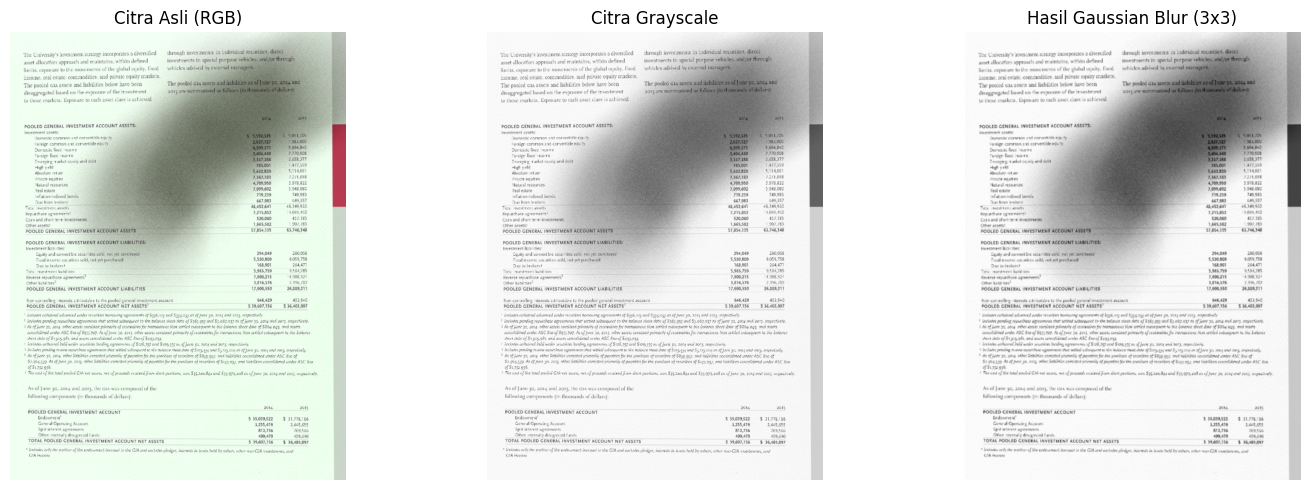

In [33]:
# 1. Preprocessing

import cv2
import numpy as np
import matplotlib.pyplot as plt

image_path_3 = 'dokumen-kusam.png' 
img_3 = cv2.imread(image_path_3)
img_3_rgb = cv2.cvtColor(img_3, cv2.COLOR_BGR2RGB)

# Konversi wajib ke Grayscale untuk Thresholding
img_3_gray = cv2.cvtColor(img_3, cv2.COLOR_BGR2GRAY)

# Penghalusan (Smoothing) ringan. 
img_3_blurred = cv2.GaussianBlur(img_3_gray, (3, 3), 0)

# Visualisasi
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img_3_rgb)
plt.title("Citra Asli (RGB)")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(img_3_gray, cmap='gray')
plt.title("Citra Grayscale")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(img_3_blurred, cmap='gray')
plt.title("Hasil Gaussian Blur (3x3)")
plt.axis('off')

plt.tight_layout()
plt.show()

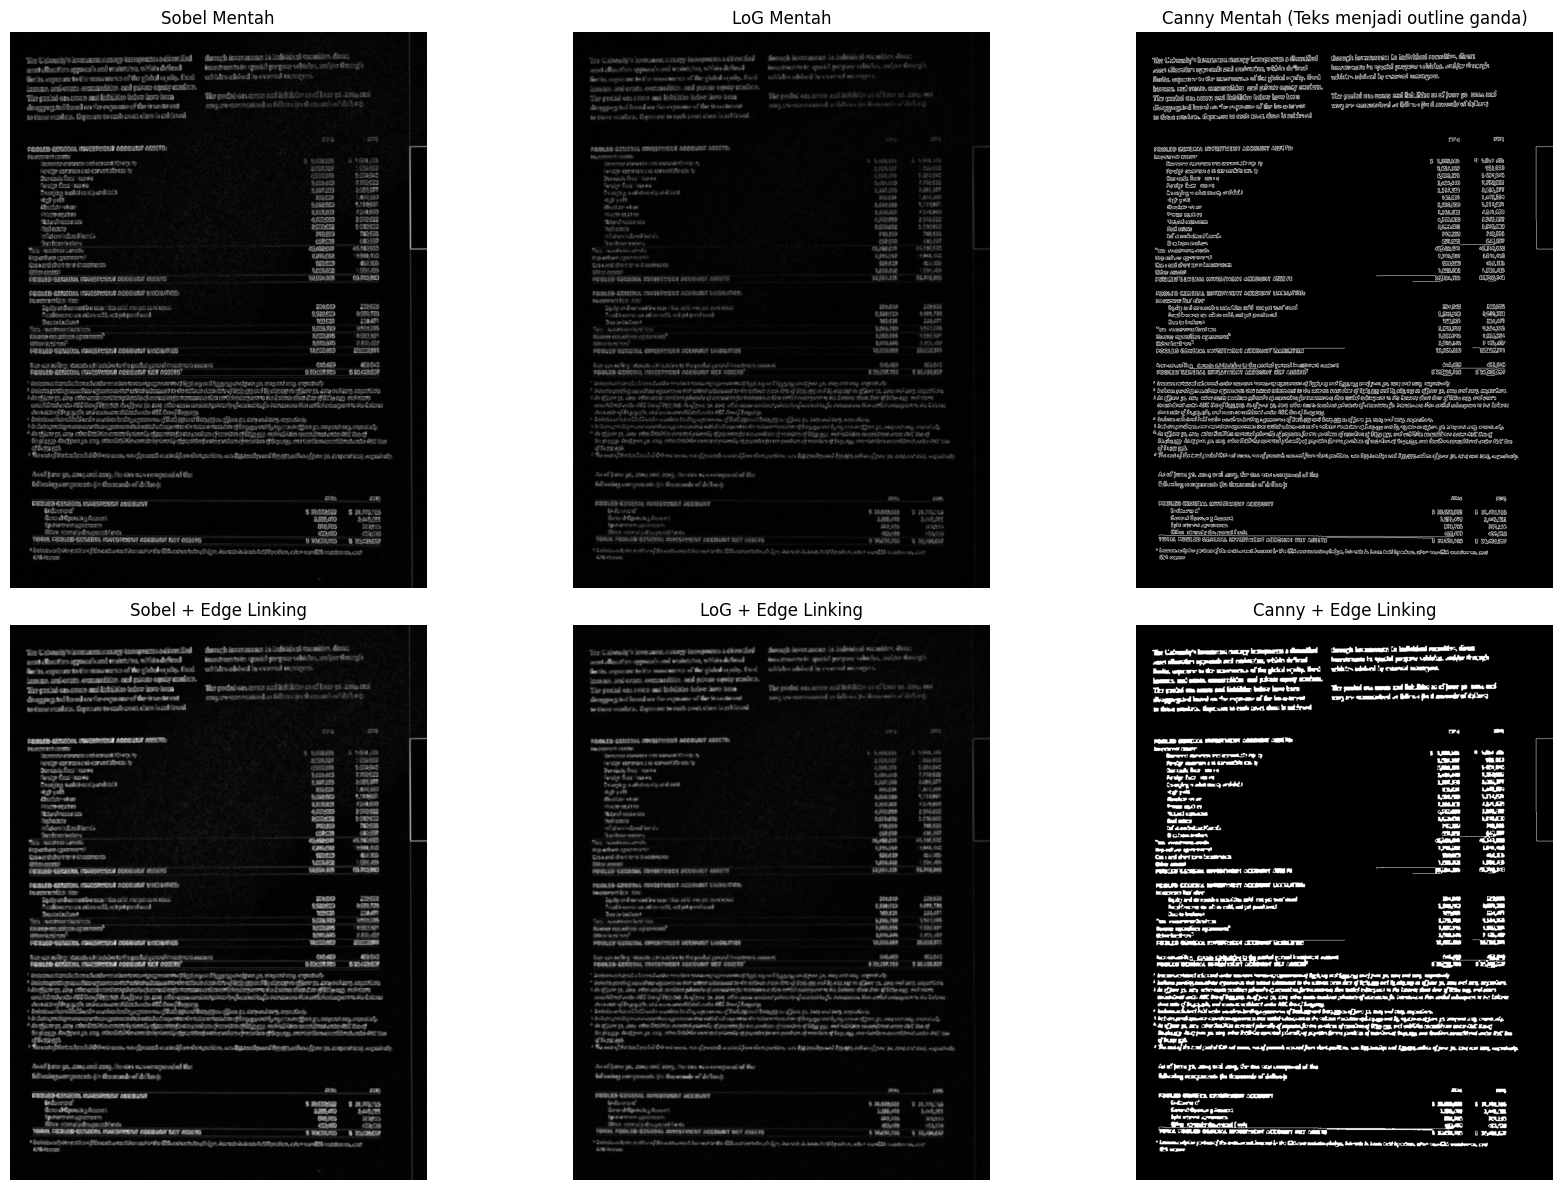

In [34]:
# 2. Segmentasi Diskontinuitas

kernel_3 = np.ones((3,3), np.uint8)

# 1. Sobel Edge Detection
sobelx_3 = cv2.Sobel(img_3_blurred, cv2.CV_64F, 1, 0, ksize=3)
sobely_3 = cv2.Sobel(img_3_blurred, cv2.CV_64F, 0, 1, ksize=3)
sobel_combined_3 = cv2.magnitude(sobelx_3, sobely_3)
sobel_combined_3 = np.uint8(255 * sobel_combined_3 / np.max(sobel_combined_3))
# Edge Linking
sobel_linked_3 = cv2.morphologyEx(sobel_combined_3, cv2.MORPH_CLOSE, kernel_3)

# 2. Laplacian of Gaussian (LoG)
laplacian_3 = cv2.Laplacian(img_3_blurred, cv2.CV_64F)
laplacian_3 = np.uint8(np.absolute(laplacian_3))
# Edge Linking
log_linked_3 = cv2.morphologyEx(laplacian_3, cv2.MORPH_CLOSE, kernel_3)

# 3. Canny Edge Detection
canny_3 = cv2.Canny(img_3_blurred, 50, 150)
# Edge Linking
canny_linked_3 = cv2.morphologyEx(canny_3, cv2.MORPH_CLOSE, kernel_3)

# Visualisasi
plt.figure(figsize=(18, 12))

# Baris 1: Hasil Mentah
plt.subplot(2, 3, 1)
plt.imshow(sobel_combined_3, cmap='gray')
plt.title("Sobel Mentah")
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(laplacian_3, cmap='gray')
plt.title("LoG Mentah")
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(canny_3, cmap='gray')
plt.title("Canny Mentah (Teks menjadi outline ganda)")
plt.axis('off')

# Baris 2: Hasil setelah Edge Linking
plt.subplot(2, 3, 4)
plt.imshow(sobel_linked_3, cmap='gray')
plt.title("Sobel + Edge Linking")
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(log_linked_3, cmap='gray')
plt.title("LoG + Edge Linking")
plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(canny_linked_3, cmap='gray')
plt.title("Canny + Edge Linking")
plt.axis('off')

plt.tight_layout()
plt.show()

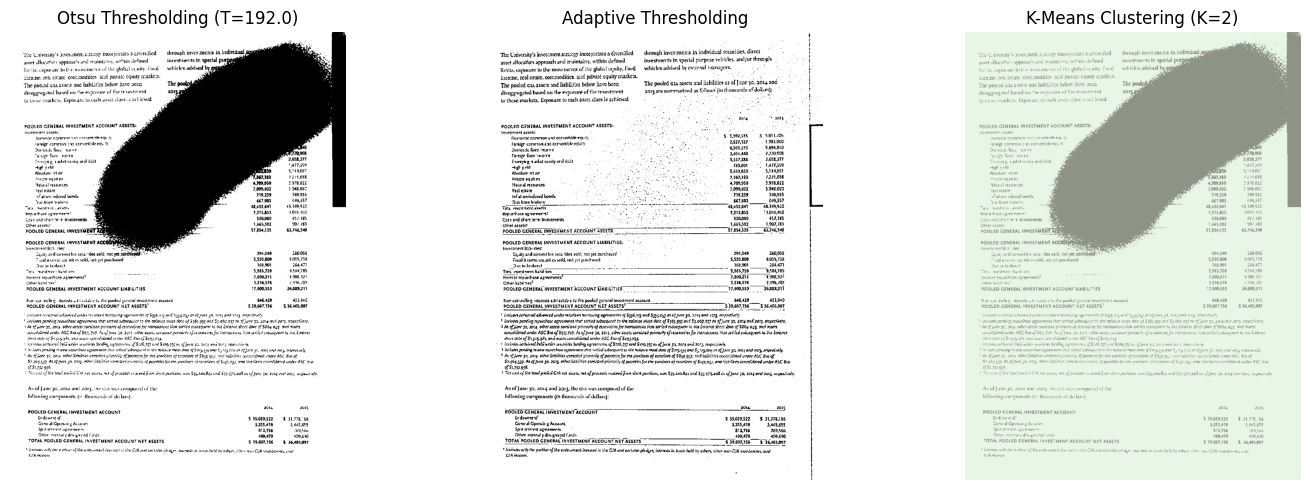

In [35]:
# 3. Segmentasi Similaritas

# 1. Otsu Thresholding (Global)
ret_otsu_3, otsu_result_3 = cv2.threshold(img_3_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 2. Adaptive Thresholding (Lokal)
adaptive_result_3 = cv2.adaptiveThreshold(img_3_gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                        cv2.THRESH_BINARY, 21, 10)

# 3. K-Means Clustering (Berbasis Warna RGB)
pixel_values_3 = img_3_rgb.reshape((-1, 3))
pixel_values_3 = np.float32(pixel_values_3)

k_clusters_3 = 2
criteria_3 = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)
_, labels_3, centers_3 = cv2.kmeans(pixel_values_3, k_clusters_3, None, criteria_3, 10, cv2.KMEANS_RANDOM_CENTERS)

centers_3 = np.uint8(centers_3)
kmeans_result_3 = centers_3[labels_3.flatten()].reshape(img_3_rgb.shape)

# Visualisasi
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(otsu_result_3, cmap='gray')
plt.title(f"Otsu Thresholding (T={ret_otsu_3})")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(adaptive_result_3, cmap='gray')
plt.title("Adaptive Thresholding")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(kmeans_result_3)
plt.title(f"K-Means Clustering (K={k_clusters_3})")
plt.axis('off')

plt.tight_layout()
plt.show()

**Analisis Citra 3:**

* **Kualitas Segmentasi:**
    * **Diskontinuitas:** Gagal total. Canny membuat *outline* ganda pada huruf. *Edge Linking* menyebabkan spasi antar huruf menyatu menjadi gumpalan balok putih yang tidak bisa dibaca.
    * **Similaritas:** 
        * **Adaptive Thresholding:** Berhasil mempertahankan ketajaman teks baik di area terang maupun area bayangan pekat.
        * **Otsu & K-Means:** Gagal, Otsu mengubah area bayangan menjadi blok hitam pekat (*under-segmentation*). K-Means gagal memisahkan tinta dari kertas gelap.

* **Kelebihan Metode:**
    * **Adaptive Thresholding:** Kebal terhadap pencahayaan tidak merata (bayangan). Menghitung *threshold* secara lokal memungkinkan algoritma membedakan "hitam tinta" dan "hitam kertas" secara independen.

* **Kekurangan Metode:**
    * **Otsu:** Histogram globalnya rusak oleh area bayangan, sehingga area gelap dipukul rata menjadi hitam.
    * **Diskontinuitas (Canny + Morfologi):** Ekstraksi kontur merusak struktur huruf kecil. Morfologi *closing* mengisi celah antar huruf menjadi gumpalan biner.

* **Kesesuaian Metode:**
    * **Sangat Sesuai:** Adaptive Thresholding (Standar industri untuk OCR dokumen kusam/berbayang).
    * **Sangat Tidak Sesuai:** Diskontinuitas, Otsu, dan K-Means.

## IV. Tabel dan Analisis Akhir

| Metode | Keunggulan Utama | Kelemahan Fatal | Cocok Untuk Karakteristik... |
| :--- | :--- | :--- | :--- |
| **Sobel & LoG** | Komputasi ringan untuk ekstraksi tepi dasar. | Hancur oleh *noise*/tekstur; gagal mendeteksi batas kabur. | Objek berukuran besar dengan kontras sangat tajam. |
| **Canny** | Mampu menambal garis tepi yang terputus di area persinggungan objek. | Menggumpalkan struktur mikro/rapat (teks) menjadi blok biner padat. | **Objek Berhimpitan** (koin, sel biologi). |
| **Otsu Thresholding** | Sangat cepat memisahkan dua kelas intensitas secara otomatis. | Buta batas objek yang menumpuk; hancur oleh pencahayaan tidak merata (bayangan). | Objek tunggal/siluet dengan pencahayaan ideal. |
| **Adaptive Thresholding** | Sangat tangguh menyelamatkan detail pada iluminasi asimetris/bayangan gelap. | *Over-segmentation* ekstrem (penuh *noise*) pada area gradasi warna yang seragam (langit). | **Dokumen Berbayang / Kusam** (ekstraksi teks). |
| **K-Means** | Sukses memetakan gradasi warna tanpa membutuhkan eksistensi garis tepi fisik. | Salah klasterisasi jika dua area berbeda memiliki metrik RGB yang berdekatan. | **Batas Kabur** (langit, awan, gas). |

Hasil dari pengujian ini: Tidak ada algoritma segmentasi universal. Kegagalan algoritma murni disebabkan oleh ketidakcocokan antara logika matematis metode tersebut dengan karakteristik piksel pada citra.